<a href="https://colab.research.google.com/github/hohohoo07/Advanced_software_Lab./blob/main/AS_Week11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 심화전공실습: 딥러닝과 합성곱 신경망 기초

8×8 손글씨 숫자 데이터로 이미지 분류 모델을 학습합니다.

- 위에서 아래로 순서대로 실행하세요.
- Google Colab에서 TensorFlow를 사용합니다.
- 데이터: scikit-learn 내장 digits. MNIST와 다릅니다.
- 테스트 데이터는 최종 모델 선택 후 한 번 평가합니다.
- 아래 코드의 기본 실험은 Dense와 CNN을 검증 데이터로 비교한 다음 CNN을 평가합니다.


## 1. 환경과 라이브러리


In [ ]:
from pathlib import Path
import json
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
import matplotlib
matplotlib.use('Agg') if os.environ.get('WEEK11_HEADLESS') else None
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass
OUT = Path('week11_results')
OUT.mkdir(exist_ok=True)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


## 2. 데이터 확인: MNIST와 다른 8x8 데이터입니다.


images: (1797, 8, 8) labels: (1797,)
pixel range: 0.0 16.0


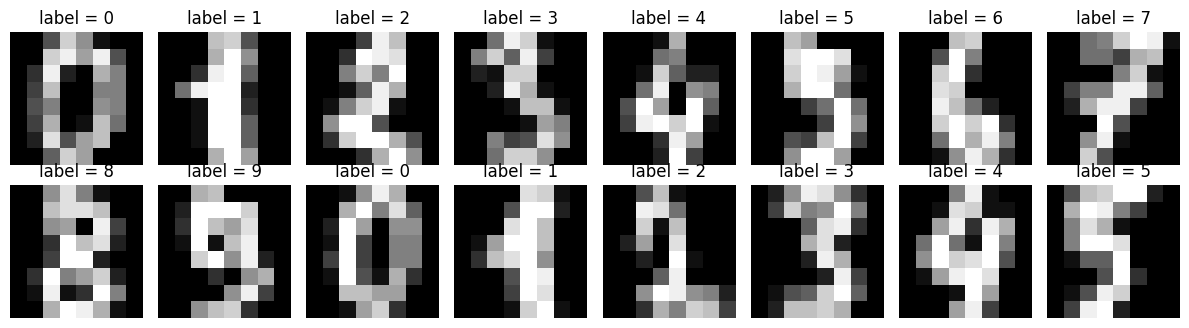

In [ ]:
digits = load_digits()
images = digits.images.astype('float32')
labels = digits.target.astype('int64')
print('images:', images.shape, 'labels:', labels.shape)
print('pixel range:', images.min(), images.max())
fig, axes = plt.subplots(2, 8, figsize=(12, 3.3))
for ax, image, label in zip(axes.ravel(), images, labels):
    ax.imshow(image, cmap='gray', vmin=0, vmax=16, interpolation='nearest')
    ax.set_title(f'label = {label}')
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'samples.png', dpi=180)
plt.show()

## 3. 분할: 같은 표본이 서로 다른 분할에 들어가지 않도록 인덱스로 분리


In [ ]:
all_ids = np.arange(len(images))
trainval_ids, test_ids = train_test_split(
    all_ids, test_size=0.20, stratify=labels, random_state=42)
train_ids, val_ids = train_test_split(
    trainval_ids, test_size=0.25,
    stratify=labels[trainval_ids], random_state=42)
assert not (set(train_ids) & set(val_ids))
assert not (set(train_ids) & set(test_ids))
assert not (set(val_ids) & set(test_ids))

def prepare(ids):
    return images[ids, ..., np.newaxis] / 16.0, labels[ids]

x_train, y_train = prepare(train_ids)
x_val, y_val = prepare(val_ids)
x_test, y_test = prepare(test_ids)
print('train/validation/test:', len(train_ids), len(val_ids), len(test_ids))
print('input:', x_train.shape, x_train.dtype)
np.savez_compressed(OUT / 'digits_split.npz', images=images, labels=labels,
                    train_ids=train_ids, val_ids=val_ids, test_ids=test_ids)

train/validation/test: 1077 360 360
input: (1077, 8, 8, 1) float32


## 4. Dense 기준 모델


In [ ]:
def build_dense():
    return keras.Sequential([
        keras.Input(shape=(8, 8, 1)),
        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name='dense_baseline')

## 5. CNN 모델: same 패딩으로 공간 크기 유지


In [ ]:
def build_cnn(filters=16):
    return keras.Sequential([
        keras.Input(shape=(8, 8, 1)),
        layers.Conv2D(filters, 3, padding='same', activation='relu', name='conv1'),
        layers.MaxPooling2D(2, name='pool1'),
        layers.Conv2D(filters * 2, 3, padding='same', activation='relu', name='conv2'),
        layers.MaxPooling2D(2, name='pool2'),
        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name='cnn_digits')

cnn = build_cnn()
cnn.summary()
assert cnn.count_params() == 9258

Model: "cnn_digits"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 2, 2, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,258 (36.16 KB)

 Trainable params: 9,258 (36.16 KB)

 Non-trainable params: 0 (0.00 B)

## 6. 학습: 검증 데이터만 학습 중 참조합니다.


In [ ]:
def train_model(model, max_epochs=20):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
                  metrics=['accuracy'])
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True)
    # 작은 CPU 환경에서 스레드 폭증 방지. Colab에서도 같은 데이터 흐름입니다.
    opts = tf.data.Options()
    opts.threading.private_threadpool_size = 1
    train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    train_ds = train_ds.shuffle(len(x_train), seed=42,
                               reshuffle_each_iteration=True).batch(32).with_options(opts)
    val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(32).with_options(opts)
    history = model.fit(train_ds, validation_data=val_ds,
                        epochs=max_epochs, callbacks=[early_stop], verbose=2)
    return history

baseline = build_dense()
base_history = train_model(baseline)
history = train_model(cnn)
base_val = baseline.evaluate(x_val, y_val, verbose=0)
cnn_val = cnn.evaluate(x_val, y_val, verbose=0)
print('Dense validation:', base_val)
print('CNN validation:', cnn_val)

Epoch 1/20
34/34 - 1s - 29ms/step - accuracy: 0.1708 - loss: 2.2921 - val_accuracy: 0.2167 - val_loss: 2.1518
Epoch 2/20
34/34 - 0s - 2ms/step - accuracy: 0.3798 - loss: 2.0091 - val_accuracy: 0.4583 - val_loss: 1.8690
Epoch 3/20
34/34 - 0s - 2ms/step - accuracy: 0.6416 - loss: 1.7021 - val_accuracy: 0.6806 - val_loss: 1.5540
Epoch 4/20
34/34 - 0s - 2ms/step - accuracy: 0.7586 - loss: 1.3876 - val_accuracy: 0.8111 - val_loss: 1.2577
Epoch 5/20
34/34 - 0s - 2ms/step - accuracy: 0.8403 - loss: 1.1164 - val_accuracy: 0.8528 - val_loss: 1.0332
Epoch 6/20
34/34 - 0s - 3ms/step - accuracy: 0.8644 - loss: 0.9118 - val_accuracy: 0.8833 - val_loss: 0.8596
Epoch 7/20
34/34 - 0s - 2ms/step - accuracy: 0.8839 - loss: 0.7560 - val_accuracy: 0.8944 - val_loss: 0.7370
Epoch 8/20
34/34 - 0s - 2ms/step - accuracy: 0.9025 - loss: 0.6388 - val_accuracy: 0.9139 - val_loss: 0.6349
Epoch 9/20
34/34 - 0s - 2ms/step - accuracy: 0.9136 - loss: 0.5509 - val_accuracy: 0.9139 - val_loss: 0.5595
Epoch 10/20
34/34 

## 7. 학습 곡선: 실제 결과를 읽습니다.


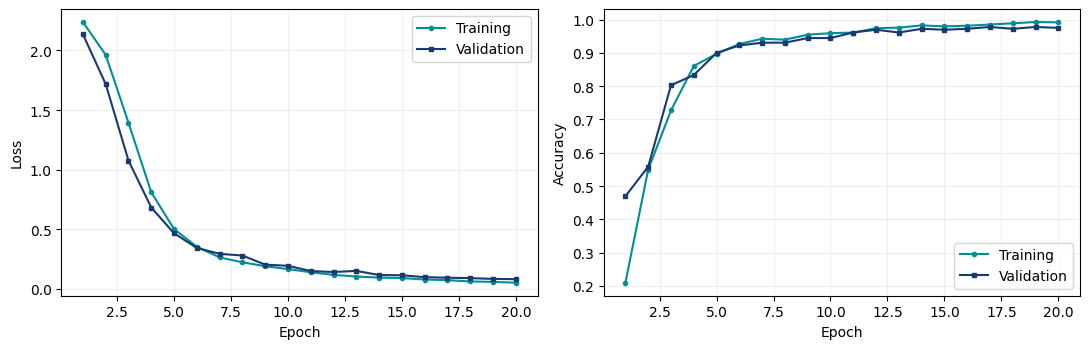

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, key, title in zip(axes, ['loss', 'accuracy'], ['Loss', 'Accuracy']):
    ep = np.arange(1, len(history.history[key]) + 1)
    ax.plot(ep, history.history[key], label='Training', color='#008e97', marker='o', ms=3)
    ax.plot(ep, history.history['val_' + key], label='Validation', color='#173b70', marker='s', ms=3)
    ax.set(xlabel='Epoch', ylabel=title)
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'learning_curves.png', dpi=180)
plt.show()

## 8. 선택을 마친 CNN을 테스트 데이터로 최종 평가


CNN test loss=0.0880, accuracy=0.9667


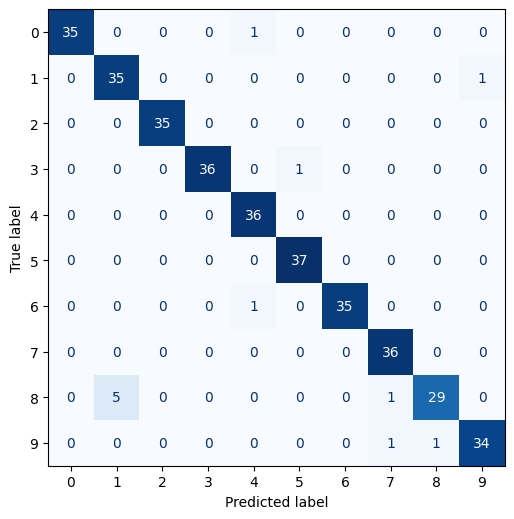

In [ ]:
# 실험을 추가한다면 이 셀 실행을 마지막으로 미루세요.
test_loss, test_acc = cnn.evaluate(x_test, y_test, verbose=0)
prob = cnn.predict(x_test, verbose=0)
pred = prob.argmax(axis=1)
print(f'CNN test loss={test_loss:.4f}, accuracy={test_acc:.4f}')
cm = confusion_matrix(y_test, pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(6.3, 5.3))
ConfusionMatrixDisplay(cm, display_labels=np.arange(10)).plot(
    ax=ax, colorbar=False, cmap='Blues', values_format='d')
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrix.png', dpi=180)
plt.show()

## 9. 예측 및 오분류 확인


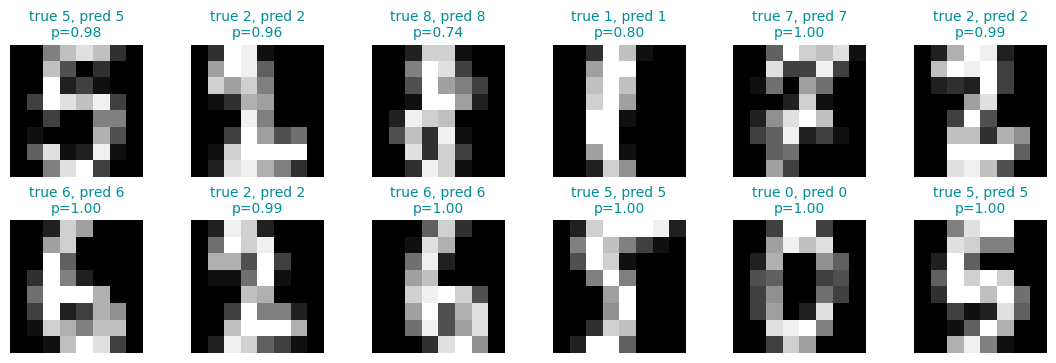

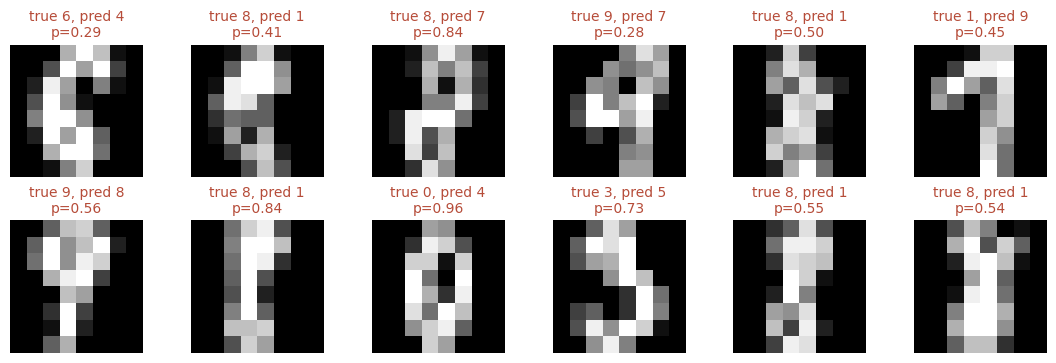

In [ ]:
for ids, name in [(np.arange(12), 'predictions'),
                  (np.flatnonzero(pred != y_test)[:12], 'mistakes')]:
    if len(ids) == 0:
        print('No misclassified samples in this run.')
        continue
    fig, axes = plt.subplots(2, 6, figsize=(11, 3.7))
    for ax in axes.ravel():
        ax.axis('off')
    for ax, idx in zip(axes.ravel(), ids):
        ax.imshow(x_test[idx, ..., 0], cmap='gray', vmin=0, vmax=1)
        ax.set_title(f'true {y_test[idx]}, pred {pred[idx]}\np={prob[idx, pred[idx]]:.2f}',
                     color='#008e97' if pred[idx] == y_test[idx] else '#b64c39', fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT / f'{name}.png', dpi=180)
    plt.show()

## 10. 첫 합성곱 층의 반응: 채널별 값은 직접 확인해야 합니다.


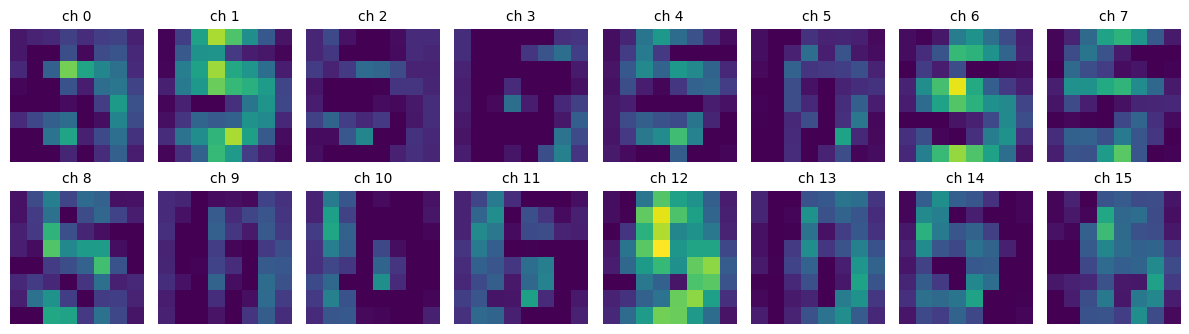

In [ ]:
feature_model = keras.Model(inputs=cnn.inputs, outputs=cnn.get_layer('conv1').output)
features = feature_model.predict(x_test[:1], verbose=0)[0]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ch, ax in enumerate(axes.ravel()):
    ax.imshow(features[..., ch], cmap='viridis', vmin=0, vmax=max(float(features.max()), 1e-6))
    ax.set_title(f'ch {ch}', fontsize=10)
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'feature_maps.png', dpi=180)
plt.show()

## 11. 저장과 재사용


In [ ]:
cnn.save(OUT / 'digits_cnn.keras')
restored = keras.models.load_model(OUT / 'digits_cnn.keras')
np.testing.assert_allclose(restored.predict(x_test[:3], verbose=0), prob[:3], atol=1e-6)
summary = {
    'dataset': 'sklearn.datasets.load_digits',
    'split_counts': [len(train_ids), len(val_ids), len(test_ids)],
    'seed': 42, 'tensorflow': tf.__version__,
    'baseline_params': baseline.count_params(), 'cnn_params': cnn.count_params(),
    'baseline_validation': {'loss': float(base_val[0]), 'accuracy': float(base_val[1])},
    'cnn_validation': {'loss': float(cnn_val[0]), 'accuracy': float(cnn_val[1])},
    'cnn_test': {'loss': float(test_loss), 'accuracy': float(test_acc)},
    'baseline_history': base_history.history, 'cnn_history': history.history,
    'confusion_matrix': cm.tolist(), 'first_prediction': prob[0].tolist(),
    'first_true': int(y_test[0]), 'first_pred': int(pred[0]),
    'misclassified_count': int((pred != y_test).sum())
}
(OUT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Saved:', OUT.resolve())

Saved: /content/week11_results


## 선택 실험: 한 항목만 바꾸고 검증 결과로 비교


In [ ]:
# 1) build_cnn(filters=8)과 기본 모델의 검증 정확도 및 파라미터 수 비교
# 2) train_model의 max_epochs 변경. EarlyStopping 때문에 실제 epoch는 다를 수 있습니다.
# 테스트 데이터는 실험 선택에 사용하지 마세요.
# 모델 변경 후 feature-map 표시 코드는 채널 수에 맞게 조절하세요.

## 데이터와 API 출처

- 데이터: E. Alpaydin & C. Kaynak, Optical Recognition of Handwritten Digits, UCI Machine Learning Repository (1998), https://doi.org/10.24432/C50P49
- scikit-learn: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
- Keras Conv2D: https://keras.io/api/layers/convolution_layers/convolution2d/
- Keras MaxPooling2D: https://keras.io/api/layers/pooling_layers/max_pooling2d/
- Keras losses: https://keras.io/api/losses/probabilistic_losses/
- Keras EarlyStopping: https://keras.io/api/callbacks/early_stopping/
